# HDD 06 — Partition-conditioned anomaly scoring experiment
**VS Code / local Jupyter.** Run independently after Notebook 05B. This loads its existing encoder and partition; it does not train them again.

## Review of your completed 05B run
- Training completed through epoch 50; best checkpoint was epoch 44, stopping MSE approximately 0.004440. The original encoder's best stopping MSE was approximately 0.004863. This is a modest optimisation improvement, not proof of improved anomaly detection.
- The levels-plus-changes encoder produced two candidates passing all three drive-resampling tests. `mcs30_ms15` was selected: sampled DBCV 0.530406, minimum jointly assigned ARI 1.0, minimum jointly assigned fraction 0.849.
- Its training assignments had zero switching drives and zero persistence lift. It supports a repeatable partition of drive behaviour, but the run does not demonstrate temporal regime switching.
- Neither the original encoder nor the simple change-summary baseline met the stable-partition checks.

**Next question:** does distance from that stable partition improve a reconstruction-only detector? Does conditioning calibration on the partition help or hide unusual behaviour?

This is an explicitly versioned **experimental ablation** of the proposal's Detect stage. Transition weight is fixed to zero because transitions were not supported in the current training data. It does not complete the proposed three-component score, validate operating-regime semantics, implement drift adaptation, or evaluate real failure prediction. June and outcome labels remain closed.

Compare fixed detectors and report every result:
1. Mean reconstruction error over days/features (R).
2. Final-day temperature reconstruction error (E), a specialised spike-screening reference motivated by the earlier diagnostics; the new encoder must earn its own sensitivity result.
3. Nearest normalised training-prototype distance (D).
4. Equal-weight training-normalised reconstruction plus distance (RD), with no weight search.

For each, compare global April calibration with partition-conditional April calibration where enough distinct drives support the conditional estimate. There is no automatic winner selection, and no rule that ORs the eight alternatives together.


## 1. Dependencies and paths
Use the existing VS Code kernel. The component path matches your prior notebooks. Change it only if the repository moved. Choose a new SCORE_ID when changing settings; original results are preserved.


In [1]:
%pip -q install "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.4,<2" "pyarrow>=16" "hdbscan>=0.8.40,<0.9" torch joblib matplotlib tqdm


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import json, hashlib, os, platform, warnings
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, joblib, hdbscan
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from hdbscan.prediction import approximate_predict
from tqdm.auto import tqdm

COMPONENT_ROOT=Path(r'D:/SLIIT/Y4S1/RP/Research/J26-DS-342-/01_component_1_behavioral_drift_genai')
RUN_ID='single_model_q1q2_2021_v1'
ABLATION_ID='representation_ablation_v1_seed42'
SCORE_ID='partition_scoring_v1'
REPRESENTATION='level_change_encoder'
SEED=42

def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()

ABLATION_OUT=COMPONENT_ROOT/'results'/RUN_ID/ABLATION_ID
ablation_path=ABLATION_OUT/'representation_ablation_complete.json'
if not ablation_path.is_file():raise FileNotFoundError(f'Complete Notebook 05B, or correct the paths. Expected: {ablation_path.resolve()}')
ablation=json.loads(ablation_path.read_text())
assert ablation['analysis_complete'] and ablation['training_complete'], 'Notebook 05B training must be complete.'
assert ablation['failure_labels_used'] is False and ablation['sealed_test_opened'] is False
for relative,digest in ablation['artifact_sha256'].items():
    assert sha256(COMPONENT_ROOT/relative)==digest, f'Changed 05B artifact: {relative}'
selected=[r for r in ablation['representations'] if r['representation']==REPRESENTATION]
assert len(selected)==1 and selected[0]['stable_partition'] is True, 'The declared representation must pass partition stability; do not flip its saved flag.'
print('Selected partition:',selected[0]['candidate'],'| Temporal evidence:',selected[0]['temporal_evidence'])
if not selected[0]['temporal_evidence']:print('Temporal regime evidence absent. Transition score remains disabled.')
complete_path=COMPONENT_ROOT/'experiments'/RUN_ID/'dataset_complete.json'
assert sha256(complete_path)==ablation['settings']['dataset_complete_sha256']
complete=json.loads(complete_path.read_text());assert complete['status']=='passed'
for relative,digest in complete['working_hashes'].items():assert sha256(COMPONENT_ROOT/relative)==digest, f'Changed data: {relative}'
config_path=COMPONENT_ROOT/'config'/f'{RUN_ID}.json';assert sha256(config_path)==complete['config_sha256']
cfg=json.loads(config_path.read_text());FEATURES=cfg['raw_features'];T=cfg['window_days'];F=len(FEATURES)
ABLATION_MODELS=COMPONENT_ROOT/'models/trained'/RUN_ID/ABLATION_ID
ENC_SETTINGS=json.loads((ABLATION_MODELS/'settings.json').read_text())
delta_path=ABLATION_MODELS/'change_preprocessing.json';delta=json.loads(delta_path.read_text())
prep_path=COMPONENT_ROOT/'models/trained'/f'{RUN_ID}_daily_preprocessing.json'
assert sha256(prep_path)==ablation['settings']['daily_preprocessing_sha256']
prep=json.loads(prep_path.read_text());assert prep['features']==FEATURES==delta['features']
pipeline_path=ABLATION_MODELS/f'{REPRESENTATION}_diagnostic_pipeline.joblib'
pipeline=joblib.load(pipeline_path)  # Load only your own trusted artifacts.
assert pipeline['stable_partition'] is True and pipeline['candidate']==selected[0]['candidate']
OUT=COMPONENT_ROOT/'results'/RUN_ID/SCORE_ID
MODEL_DIR=COMPONENT_ROOT/'models/trained'/RUN_ID/SCORE_ID
for folder in [OUT,MODEL_DIR,OUT/'synthetic_cache']:folder.mkdir(parents=True,exist_ok=True)
SETTINGS={'seed':SEED,'calibration_quantile':.99,'conditional_minimum_windows':200,'conditional_minimum_drives':5,
    'minimum_assignment_strength':.5,'prototype_minimum_drives':5,'prototype_minimum_windows':30,
    'prototype_radius_quantile':.95,'reconstruction_weight':.5,'distance_weight':.5,'transition_weight':0.,
    'ablation_complete_sha256':sha256(ablation_path),'calibration_rule':'global and conditional quantiles compared separately; sparse/noise/weak context falls back to global',
    'synthetic_tests':['temperature_plus_2_last_7_days','temperature_plus_5_last_7_days','temperature_spike_plus_10',
        'temperature_frozen_last_7_days','temperature_alignment_break','sector_5_plus_8_last_7_days','sector_197_198_plus_8_last_7_days']}
settings_path=MODEL_DIR/'settings.json'
if settings_path.exists() and json.loads(settings_path.read_text())!=SETTINGS:raise ValueError('Scoring settings changed. Use a new SCORE_ID.')
settings_path.write_text(json.dumps(SETTINGS,indent=2))
print('Results:',OUT)


Selected partition: mcs30_ms15 | Temporal evidence: False
Temporal regime evidence absent. Transition score remains disabled.
Results: D:\SLIIT\Y4S1\RP\Research\J26-DS-342-\01_component_1_behavioral_drift_genai\results\single_model_q1q2_2021_v1\partition_scoring_v1


c:\Users\IMAKA\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load saved working representations and original windows
These are the same training/April/May cohorts used before. Check exact metadata alignment before comparing scores. No June files are read.

Reconstruction R averages over time and features; E explicitly targets the final-day temperature residual. Report both so that short anomalies are not hidden by one average. E alone is not a general five-attribute fault detector.


In [4]:
RAW,META,RESULTS={},{},{}
FEATURE_ROOT=COMPONENT_ROOT/'data/features'/RUN_ID
for split in ['train','calibration','development']:
    folder=FEATURE_ROOT/ABLATION_ID/'new_encoder'/split
    with np.load(folder/'representations.npz') as data:RESULTS[split]={k:data[k] for k in data.files}
    META[split]=pd.read_parquet(folder/'metadata.parquet').reset_index(drop=True)
    pd.testing.assert_frame_equal(META[split],pd.read_parquet(FEATURE_ROOT/split/'metadata.parquet').reset_index(drop=True))
    with np.load(FEATURE_ROOT/split/'windows_raw.npz') as data:RAW[split]=data['X'].astype(np.float32)
    assert RAW[split].shape==(len(META[split]),T,F)
    assert RESULTS[split]['feature_errors'].shape==RESULTS[split]['last_day_errors'].shape==(len(META[split]),F)
    for values in RESULTS[split].values():assert np.isfinite(values).all()
    print(split,len(META[split]),'windows |',META[split]['serial_number'].nunique(),'drives')
for a in META:
    for b in META:
        if a!=b:assert set(META[a]['serial_number']).isdisjoint(META[b]['serial_number'])
TEMPERATURE=FEATURES.index('smart_194_raw')

def transform_embedding(embedding):
    # Match Notebook 05B: convert BEFORE applying the scaler.
    embedding = np.ascontiguousarray(
        embedding,
        dtype=np.float64
    )

    scaled = pipeline["scaler"].transform(embedding)
    coordinates = pipeline["pca"].transform(scaled)

    return np.ascontiguousarray(
        coordinates,
        dtype=np.float64
    )

def assign_embedding(embedding):
    z=transform_embedding(embedding)
    labels,strengths=approximate_predict(pipeline['clusterer'],z)
    assert np.isfinite(strengths).all()
    return z,labels.astype(int),strengths

COORDINATES,LABELS,STRENGTHS={},{},{}
for split in RESULTS:
    COORDINATES[split],LABELS[split],STRENGTHS[split]=assign_embedding(RESULTS[split]['embeddings'])
    previous=pd.read_csv(ABLATION_OUT/REPRESENTATION/f'{split}_assignments.csv')
    np.testing.assert_array_equal(LABELS[split],previous['regime_label'].to_numpy())
print('Frozen assignments reproduce Notebook 05B.')


train 42578 windows | 700 drives
calibration 4410 windows | 147 drives
development 4642 windows | 150 drives
Frozen assignments reproduce Notebook 05B.


## 3. Training prototypes and component normalisation
A prototype is the median of confident training assignments. Retain clusters supported by at least five training drives and 30 windows. Scale each prototype's distances by its own training 95th distance percentile, then take the nearest scaled distance. This is a relative geometric score, not a health label or a calibrated probability.

Apply log1p to R and D, then centre/scale with training median/IQR. If IQR is effectively zero, use the training 95th percentile minus median; if still zero, use 1. Save these choices explicitly. Do not normalise using May or injected examples.

RD = 0.5 × normalised R + 0.5 × normalised D. The transition weight is zero. Fixed weights are an initial ablation; final tuning and final independent evaluation remain outstanding.


In [5]:
prototype_labels=[];centers=[];radii=[];prototype_rows=[]
for label in sorted(set(LABELS['train'])-{-1}):
    eligible=(LABELS['train']==label)&(STRENGTHS['train']>=SETTINGS['minimum_assignment_strength'])
    n_drives=META['train'].loc[eligible,'serial_number'].nunique()
    if eligible.sum()<SETTINGS['prototype_minimum_windows'] or n_drives<SETTINGS['prototype_minimum_drives']:continue
    center=np.median(COORDINATES['train'][eligible],axis=0)
    distances=np.linalg.norm(COORDINATES['train'][eligible]-center,axis=1)
    radius=max(float(np.quantile(distances,SETTINGS['prototype_radius_quantile'])),1e-12)
    prototype_labels.append(label);centers.append(center);radii.append(radius)
    prototype_rows.append({'partition':label,'windows':int(eligible.sum()),'drives':int(n_drives),'radius_q95':radius})
if len(centers)<2:raise RuntimeError('Fewer than two training-supported prototypes. Inspect membership/support; do not force partition conditioning.')
centers=np.asarray(centers);radii=np.asarray(radii);prototype_labels=np.asarray(prototype_labels,dtype=int)
pd.DataFrame(prototype_rows).to_csv(OUT/'training_prototypes.csv',index=False)
np.savez_compressed(MODEL_DIR/'prototypes.npz',labels=prototype_labels,centers=centers,radii=radii)

def base_components(result):
    z,labels,strength=assign_embedding(result['embeddings'])
    distance_matrix=np.linalg.norm(z[:,None,:]-centers[None,:,:],axis=2)/radii[None,:]
    nearest=distance_matrix.argmin(axis=1)
    components={'R':result['feature_errors'].mean(1),'E':result['last_day_errors'][:,TEMPERATURE],
        'D':distance_matrix[np.arange(len(z)),nearest]}
    context=np.where((labels>=0)&(strength>=SETTINGS['minimum_assignment_strength'])&np.isin(labels,prototype_labels),labels,-1)
    return components,context,labels,strength,prototype_labels[nearest]

train_components,*_=base_components(RESULTS['train'])
NORMALISERS={}
for name in ['R','D']:
    value=np.log1p(train_components[name]);center=float(np.median(value))
    scale=float(np.quantile(value,.75)-np.quantile(value,.25));rule='IQR'
    if scale<=1e-12:scale=float(np.quantile(value,.95)-center);rule='q95-minus-median'
    if scale<=1e-12:scale=1.;rule='constant-scale-1'
    NORMALISERS[name]={'center':center,'scale':scale,'scale_rule':rule}

def detectors(result):
    scores,context,labels,strength,nearest=base_components(result)
    normalised={k:(np.log1p(scores[k])-NORMALISERS[k]['center'])/NORMALISERS[k]['scale'] for k in ['R','D']}
    scores['RD']=SETTINGS['reconstruction_weight']*normalised['R']+SETTINGS['distance_weight']*normalised['D']
    for v in scores.values():assert np.isfinite(v).all()
    return scores,context,labels,strength,nearest

SCORES,CONTEXT={},{ }
for split,result in RESULTS.items():SCORES[split],CONTEXT[split],_,_,_=detectors(result)
(MODEL_DIR/'component_normalisation.json').write_text(json.dumps(NORMALISERS,indent=2))
print('Supported training prototypes:',prototype_labels.tolist())


Supported training prototypes: [0, 1]


## 4. Freeze global and conditional April thresholds
Each detector's global threshold is its April 99th percentile. A conditional threshold is estimated only for confident contexts containing at least 200 April windows from at least five distinct drives. All other contexts, including noise, use that detector's global threshold.

These overlapping-window quantiles implement a nominal alert-budget choice. They are not a measured false-positive rate or formal coverage guarantee. Conditional fallback can change total alert burden, which must be reported. Conditioning can also normalise persistent fault-like patterns; retain the global comparison and inspect counter perturbations.

The conditional method reassigns modified windows with the same frozen predictor. Log assignment changes during sensitivity tests so movement between thresholds cannot hide behind an aggregate metric.


In [6]:
THRESHOLDS={};calibration_rows=[]
for name,values in SCORES['calibration'].items():
    global_threshold=float(np.quantile(values,SETTINGS['calibration_quantile'],method='higher'))
    groups={}
    for label in sorted(set(CONTEXT['calibration'])-{-1}):
        selected=CONTEXT['calibration']==label
        drives=int(META['calibration'].loc[selected,'serial_number'].nunique())
        supported=bool(selected.sum()>=SETTINGS['conditional_minimum_windows'] and drives>=SETTINGS['conditional_minimum_drives'])
        threshold=float(np.quantile(values[selected],SETTINGS['calibration_quantile'],method='higher')) if supported else None
        if supported:groups[str(label)]=threshold
        calibration_rows.append({'detector':name,'partition':int(label),'windows':int(selected.sum()),'drives':drives,
            'conditional_supported':supported,'conditional_threshold':threshold,'global_threshold':global_threshold})
    THRESHOLDS[name]={'global':global_threshold,'groups':groups}
calibration_support=pd.DataFrame(calibration_rows)
calibration_support.to_csv(OUT/'conditional_calibration_support.csv',index=False)
(MODEL_DIR/'thresholds.json').write_text(json.dumps(THRESHOLDS,indent=2))
display(calibration_support)

def apply_threshold(scores,contexts,name,policy):
    values=np.full(len(scores),THRESHOLDS[name]['global'],dtype=float)
    sources=np.full(len(scores),'global',dtype=object)
    if policy=='conditional':
        sources[:]='global_fallback'
        for label,threshold in THRESHOLDS[name]['groups'].items():
            select=contexts==int(label);values[select]=threshold;sources[select]=f'partition_{label}'
    elif policy!='global':raise ValueError(policy)
    return scores>values,values,sources

def alert_events(table):
    rows=[]
    for serial,part in table.loc[table['is_anomaly_candidate']].groupby('serial_number'):
        part=part.sort_values('end_date')
        groups=part['end_date'].diff().dt.days.ne(1).cumsum()
        for _,block in part.groupby(groups):rows.append({'serial_number':serial,'first_alert':block['end_date'].min(),'last_alert':block['end_date'].max(),'flagged_days':len(block),'maximum_score':float(block['score'].max())})
    return pd.DataFrame(rows,columns=['serial_number','first_alert','last_alert','flagged_days','maximum_score'])

burden=[]
for split in SCORES:
    for name,values in SCORES[split].items():
        for policy in ['global','conditional']:
            flags,thresholds,sources=apply_threshold(values,CONTEXT[split],name,policy)
            table=META[split].copy();table['score']=values;table['threshold']=thresholds;table['threshold_source']=sources
            table['partition_label']=LABELS[split];table['membership_strength']=STRENGTHS[split]
            table['is_anomaly_candidate']=flags
            table['largest_mean_error_attribute']=[FEATURES[j] for j in RESULTS[split]['feature_errors'].argmax(1)]
            table.to_csv(OUT/f'{name}_{policy}_{split}_scores.csv',index=False)
            events=alert_events(table);events.to_csv(OUT/f'{name}_{policy}_{split}_events.csv',index=False)
            burden.append({'detector':name,'policy':policy,'split':split,'windows':len(table),
                'flagged_windows':int(flags.sum()),'flagged_percent':100*float(flags.mean()),
                'drives_with_flags':int(table.loc[flags,'serial_number'].nunique()),'alert_episodes':len(events),
                'global_fallback_percent':100*float((sources=='global_fallback').mean())})
burden=pd.DataFrame(burden);burden.to_csv(OUT/'alert_burden.csv',index=False)
display(burden.loc[burden['split'].eq('development')].round(4))


,detector,partition,windows,drives,conditional_supported,conditional_threshold,global_threshold
0,R,0,1,1,False,NaN,1.872099
1,R,1,3510,127,True,0.019728,1.872099
2,E,0,1,1,False,NaN,0.273266
3,E,1,3510,127,True,0.242116,0.273266
4,D,0,1,1,False,NaN,3.727972
5,D,1,3510,127,True,1.108364,3.727972
6,RD,0,1,1,False,NaN,150.994272
7,RD,1,3510,127,True,2.069306,150.994272


,detector,policy,split,windows,flagged_windows,flagged_percent,drives_with_flags,alert_episodes,global_fallback_percent
16,R,global,development,4642,0,0.0000,0,0,0.0000
17,R,conditional,development,4642,0,0.0000,0,0,29.7717
18,E,global,development,4642,20,0.4308,13,17,0.0000
19,E,conditional,development,4642,25,0.5386,15,21,29.7717
20,D,global,development,4642,31,0.6678,1,1,0.0000
21,D,conditional,development,4642,58,1.2495,2,2,29.7717
22,RD,global,development,4642,0,0.0000,0,0,0.0000
23,RD,conditional,development,4642,1,0.0215,1,1,29.7717


## 5. Restore the trained encoder for controlled perturbations
This is the exact architecture from Notebook 05B. It loads the saved weights; no optimizer or training loop is used. Derived changes remain unavailable whenever either source reading is masked. Infer a small batch and compare it with saved outputs before scoring perturbations.

Five fixed masked passes cover every original value once. Changes are recalculated after every perturbation. Reusing original changes after modifying a level would produce inconsistent inputs.


In [7]:
class LevelChangeEncoder(nn.Module):
    def __init__(self):
        super().__init__();width=ENC_SETTINGS['width']
        self.input_projection=nn.Linear(5*F,width)
        self.position=nn.Parameter(torch.empty(1,T,width));nn.init.normal_(self.position,std=.02)
        block=nn.TransformerEncoderLayer(width,ENC_SETTINGS['heads'],ENC_SETTINGS['feedforward'],ENC_SETTINGS['dropout'],
            activation='gelu',batch_first=True,norm_first=False)
        self.encoder=nn.TransformerEncoder(block,ENC_SETTINGS['layers'],enable_nested_tensor=False)
        for layer in self.encoder.layers:
            for parameter in layer.parameters():
                if parameter.dim()>1:nn.init.xavier_uniform_(parameter)
        self.decoder=nn.Linear(width,F)
    def forward(self,levels,changes,hide):
        visible=~hide
        delta_available=torch.zeros_like(visible)
        delta_available[:,1:]=visible[:,1:] & visible[:,:-1]
        channels=torch.cat([levels.masked_fill(hide,0.),changes.masked_fill(~delta_available,0.),
            torch.ones_like(levels),hide.float(),delta_available.float()],dim=-1)
        hidden=self.encoder(self.input_projection(channels)+self.position[:,:levels.shape[1]])
        return self.decoder(hidden),hidden.mean(1)

DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type=='cpu':torch.set_num_threads(max(1,min(4,os.cpu_count() or 1)))
model=LevelChangeEncoder().to(DEVICE)
checkpoint_path=ABLATION_MODELS/'level_change_encoder.pt'
checkpoint=torch.load(checkpoint_path,map_location=DEVICE,weights_only=True)
expected_input_hash=hashlib.sha256((sha256(ABLATION_MODELS/'settings.json')+sha256(delta_path)).encode()).hexdigest()
assert checkpoint['model_input_hash']==expected_input_hash
model.load_state_dict(checkpoint['state_dict']);model.eval()
COUNT_INDICES=[FEATURES.index(f) for f in prep['log_features']]
grid=(torch.arange(T)[:,None]+torch.arange(F)[None,:])%F
PARTITIONS=[grid.eq(k) for k in range(F)]
assert torch.stack(PARTITIONS).sum(0).eq(1).all()

def raw_channels(raw):
    levels=raw.astype(np.float64,copy=True)
    for j in COUNT_INDICES:levels[...,j]=np.log1p(levels[...,j])
    levels=((levels-np.array(prep['center']))/np.array(prep['scale'])).astype(np.float32)
    change=np.diff(raw.astype(np.float64),axis=1)
    for j in COUNT_INDICES:change[...,j]=np.sign(change[...,j])*np.log1p(np.abs(change[...,j]))
    changes=np.zeros_like(raw,dtype=np.float32)
    changes[:,1:]=((change-np.array(delta['center']))/np.array(delta['scale'])).astype(np.float32)
    return levels,changes

@torch.no_grad()
def infer_raw(raw,progress=False):
    assert np.isfinite(raw).all() and (raw>=0).all()
    levels,changes=raw_channels(raw);embeddings=[];feature_errors=[];last_day=[]
    model.eval()
    loader=DataLoader(TensorDataset(torch.from_numpy(levels),torch.from_numpy(changes)),batch_size=ENC_SETTINGS['batch_size'],shuffle=False,num_workers=0)
    for x,d in (tqdm(loader,desc='Frozen encoder inference',leave=False) if progress else loader):
        x=x.to(DEVICE);d=d.to(DEVICE);errors=torch.zeros_like(x);latent=None
        for mask in PARTITIONS:
            hide=mask.to(DEVICE).unsqueeze(0).expand_as(x)
            predicted,z=model(x,d,hide)
            errors+=torch.where(hide,(predicted-x).square(),torch.zeros_like(x));latent=z if latent is None else latent+z
        embeddings.append((latent/F).cpu().numpy());feature_errors.append(errors.mean(1).cpu().numpy());last_day.append(errors[:,-1].cpu().numpy())
    result={'embeddings':np.concatenate(embeddings),'feature_errors':np.concatenate(feature_errors),'last_day_errors':np.concatenate(last_day)}
    for value in result.values():assert np.isfinite(value).all()
    return result

check=infer_raw(RAW['development'][:8])
for key in check:np.testing.assert_allclose(check[key],RESULTS['development'][key][:8],rtol=1e-3,atol=1e-4)
print('Restored model reproduces saved 05B outputs. No retraining performed.')


Restored model reproduces saved 05B outputs. No retraining performed.


## 6. Controlled sensitivity with frozen calibration
Repeat the five previous temperature perturbations and add two declared sector-count shifts. These are deliberately modified window copies, not independent failures or coherent streaming histories. A frozen value or a small temperature shift need not be anomalous in every operating context.

The denominator for new alerts is originally unflagged windows that actually changed. Count affected drives separately; overlapping windows are dependent. Compare global/conditional results and assignment changes rather than reporting a single accuracy number.

Cached synthetic representations are reusable only for the exact scoring settings, checkpoint, development input and preprocessing hashes. Cache files are validated before use.


In [8]:
def modified_windows(name):
    base=RAW['development'];changed=base.copy();temp=TEMPERATURE
    if name=='temperature_plus_2_last_7_days':changed[:,-7:,temp]+=2
    elif name=='temperature_plus_5_last_7_days':changed[:,-7:,temp]+=5
    elif name=='temperature_spike_plus_10':changed[:,-1,temp]+=10
    elif name=='temperature_frozen_last_7_days':changed[:,-7:,temp]=changed[:,-8,temp][:,None]
    elif name=='temperature_alignment_break':
        rng=np.random.default_rng(SEED+3)
        for i in range(len(changed)):changed[i,-7:,temp]=rng.permutation(changed[i,-7:,temp])
    elif name=='sector_5_plus_8_last_7_days':changed[:,-7:,FEATURES.index('smart_5_raw')]+=8
    elif name=='sector_197_198_plus_8_last_7_days':
        for feature in ['smart_197_raw','smart_198_raw']:changed[:,-7:,FEATURES.index(feature)]+=8
    else:raise ValueError(name)
    return changed

cache_identity=hashlib.sha256((sha256(settings_path)+sha256(checkpoint_path)+sha256(FEATURE_ROOT/'development'/'windows_raw.npz')+sha256(delta_path)+sha256(prep_path)).encode()).hexdigest()
sensitivity_rows=[]
for experiment in SETTINGS['synthetic_tests']:
    changed_raw=modified_windows(experiment)
    actually_changed=np.any(changed_raw!=RAW['development'],axis=(1,2))
    cache=OUT/'synthetic_cache'/f'{experiment}.npz';manifest=cache.with_suffix('.json')
    reusable=False
    if cache.exists() and manifest.exists():
        info=json.loads(manifest.read_text());reusable=info.get('identity')==cache_identity and info.get('sha256')==sha256(cache)
    if reusable:
        with np.load(cache) as a:changed={k:a[k] for k in a.files}
        print('Reusing',experiment)
    else:
        changed=infer_raw(changed_raw,progress=True)
        np.savez_compressed(cache,**changed)
        manifest.write_text(json.dumps({'identity':cache_identity,'sha256':sha256(cache)},indent=2))
    assert changed['embeddings'].shape==RESULTS['development']['embeddings'].shape
    for values in changed.values():assert np.isfinite(values).all()
    modified_scores,context,labels,strength,nearest=detectors(changed)
    assignment_change=100*float((labels!=LABELS['development']).mean())
    for name,values in modified_scores.items():
        for policy in ['global','conditional']:
            original_flag,_,_=apply_threshold(SCORES['development'][name],CONTEXT['development'],name,policy)
            modified_flag,thresholds,sources=apply_threshold(values,context,name,policy)
            eligible=(~original_flag)&actually_changed;newly=eligible&modified_flag
            new_drives=META['development'].loc[newly,'serial_number'].nunique()
            sensitivity_rows.append({'experiment':experiment,'detector':name,'policy':policy,
                'actually_changed_windows':int(actually_changed.sum()),'eligible_windows':int(eligible.sum()),
                'original_flagged':int(original_flag.sum()),'modified_flagged':int(modified_flag.sum()),
                'newly_flagged':int(newly.sum()),'drives_newly_flagged':int(new_drives),
                'new_alert_percent_of_eligible':100*float(newly.sum()/eligible.sum()) if eligible.any() else np.nan,
                'median_score_change':float(np.median(values-SCORES['development'][name])),
                'partition_changed_percent':assignment_change,
                'global_fallback_percent':100*float((sources=='global_fallback').mean())})
            details=META['development'].copy();details['score']=values;details['original_score']=SCORES['development'][name]
            details['original_flag']=original_flag;details['modified_flag']=modified_flag;details['threshold']=thresholds
            details['partition_label']=labels;details['threshold_source']=sources
            details.to_csv(OUT/f'{experiment}_{name}_{policy}.csv',index=False)
sensitivity=pd.DataFrame(sensitivity_rows);sensitivity.to_csv(OUT/'synthetic_sensitivity.csv',index=False)
display(sensitivity[['experiment','detector','policy','newly_flagged','drives_newly_flagged','new_alert_percent_of_eligible','partition_changed_percent']].round(3))


,experiment,detector,policy,newly_flagged,drives_newly_flagged,new_alert_percent_of_eligible,partition_changed_percent
0,temperature_plus_2_last_7_days,R,global,0,0,0.000,2.413
1,temperature_plus_2_last_7_days,R,conditional,0,0,0.000,2.413
2,temperature_plus_2_last_7_days,E,global,11,7,0.238,2.413
3,temperature_plus_2_last_7_days,E,conditional,7,5,0.152,2.413
4,temperature_plus_2_last_7_days,D,global,0,0,0.000,2.413
5,temperature_plus_2_last_7_days,D,conditional,4,1,0.087,2.413
6,temperature_plus_2_last_7_days,RD,global,0,0,0.000,2.413
7,temperature_plus_2_last_7_days,RD,conditional,2,1,0.043,2.413
8,temperature_plus_5_last_7_days,R,global,0,0,0.000,5.515
9,temperature_plus_5_last_7_days,R,conditional,1,1,0.022,5.515


## 7. Compare baseline burden and show score distributions
This is a development comparison across already inspected data. It must not be reported as independent test performance. Baseline scores come from Notebook 03; no baseline model or real outcome is loaded.

The global and conditional alternatives are distinct operating rules. Do not OR their alerts together, select the most favourable row from each test, or call zero unchanged alerts a zero false-positive rate. A final operating rule requires a recorded decision followed by independent evaluation.


,detector,policy,flagged_windows,flagged_percent,drives_with_flags
0,isolation_forest,Notebook03_global,35,0.754,2
1,robust_deviation,Notebook03_global,0,0.000,0
2,dense_autoencoder,Notebook03_global,31,0.668,1
3,R,global,0,0.000,0
4,R,conditional,0,0.000,0
5,E,global,20,0.431,13
6,E,conditional,25,0.539,15
7,D,global,31,0.668,1
8,D,conditional,58,1.249,2
9,RD,global,0,0.000,0


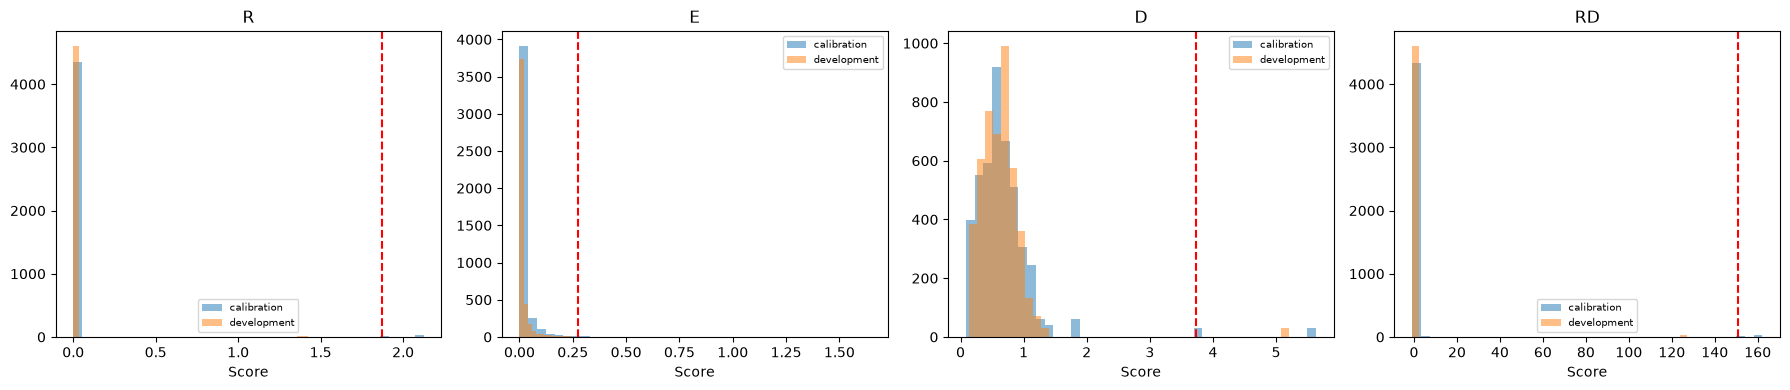

R: mean reconstruction | E: final-day temperature error | D: prototype distance | RD: equal-weight R+D


In [9]:
baseline_path=COMPONENT_ROOT/'results'/RUN_ID/'baselines_v1'/'alert_burden.csv'
if baseline_path.exists():
    baseline=pd.read_csv(baseline_path)
    for name in ['isolation_forest','robust_deviation','dense_autoencoder']:
        path=baseline_path.parent/f'{name}_development_scores.csv'
        old=pd.read_csv(path,parse_dates=['start_date','end_date'])
        pd.testing.assert_frame_equal(old[['serial_number','start_date','end_date']].reset_index(drop=True),META['development'][['serial_number','start_date','end_date']].reset_index(drop=True),check_dtype=False)
    baseline=baseline.loc[baseline['split'].eq('development')].copy();baseline['policy']='Notebook03_global'
    combined=pd.concat([baseline,burden.loc[burden['split'].eq('development')]],ignore_index=True)
    combined.to_csv(OUT/'development_baseline_burden_comparison.csv',index=False)
    display(combined[['detector','policy','flagged_windows','flagged_percent','drives_with_flags']].round(3))
else:print('Notebook 03 baseline burden file absent; current scoring results are still saved.')
fig,axes=plt.subplots(1,4,figsize=(18,4))
for ax,name in zip(axes,['R','E','D','RD']):
    for split in ['calibration','development']:ax.hist(SCORES[split][name],bins=40,alpha=.5,label=split)
    ax.axvline(THRESHOLDS[name]['global'],color='red',linestyle='--');ax.set_title(name);ax.set_xlabel('Score');ax.legend(fontsize=7)
fig.tight_layout();fig.savefig(OUT/'component_score_distributions.png',dpi=180,bbox_inches='tight');plt.show()
print('R: mean reconstruction | E: final-day temperature error | D: prototype distance | RD: equal-weight R+D')


## 8. Verify score outputs and save a reproducible scoring specification
Save the frozen normalisation, thresholds and prototypes plus the upstream model identity. Score outputs retain serial/date metadata, partition assignments, threshold source and error evidence. They are not failure probabilities or causal diagnoses.

This completion file does not declare that the combined detector is better, accept temporal regimes, or authorise opening June. The next decision must consider alert burden, affected drives, sensitivity across perturbations, conditional fallback, and whether partition changes mask unusual inputs. If RD fails to add value, retain that negative result.

Before drift adaptation: freeze a defensible scoring candidate, specify the stream unit and timing, and distinguish controlled fleet shifts from individual faults. Quarantine/retraining, five neural seeds, more models, longer follow-up and final failure-based evaluation remain outstanding.


In [10]:
for split in META:
    for name,values in SCORES[split].items():
        assert len(values)==len(META[split]) and np.isfinite(values).all()
        for policy in ['global','conditional']:
            a,_,_=apply_threshold(values,CONTEXT[split],name,policy)
            saved=pd.read_csv(OUT/f'{name}_{policy}_{split}_scores.csv')
            np.testing.assert_array_equal(a,saved['is_anomaly_candidate'].to_numpy())
# Verify threshold reload without retraining or refitting.
reloaded=json.loads((MODEL_DIR/'thresholds.json').read_text());assert reloaded==THRESHOLDS
spec={'run_id':RUN_ID,'ablation_id':ABLATION_ID,'score_id':SCORE_ID,'settings':SETTINGS,
    'detectors':{'R':'mean masked level MSE over 30 days and five features','E':'final-day temperature masked MSE',
                 'D':'minimum distance to training median prototypes / corresponding training q95 radius',
                 'RD':'0.5 training-normalised log1p(R) + 0.5 training-normalised log1p(D)'},
    'normalisation':NORMALISERS,'thresholds':THRESHOLDS,'transition_weight':0,
    'upstream_encoder_checkpoint':str(checkpoint_path.relative_to(COMPONENT_ROOT)),
    'upstream_partition_pipeline':str(pipeline_path.relative_to(COMPONENT_ROOT)),
    'checkpoint_sha256':sha256(checkpoint_path),'partition_pipeline_sha256':sha256(pipeline_path),
    'prototype_sha256':sha256(MODEL_DIR/'prototypes.npz'),
    'settings_sha256':sha256(settings_path),'ablation_complete_sha256':sha256(ablation_path)}
(MODEL_DIR/'scoring_specification.json').write_text(json.dumps(spec,indent=2,allow_nan=False))
record={'created_utc':datetime.now(timezone.utc).isoformat(),'analysis_complete':True,'score_id':SCORE_ID,
    'run_id':RUN_ID,'specification_sha256':sha256(MODEL_DIR/'scoring_specification.json'),
    'real_failure_labels_used':False,'sealed_test_opened':False,'transition_score_enabled':False,
    'temporal_regimes_validated':False,'winner_selected':False,
    'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'torch':str(torch.__version__),'hdbscan':version('hdbscan')},
    'limitations':['single seed/model','exploratory sequential development','unlabeled training/calibration contamination',
        'stable partitions do not prove temporal operating regimes','conditional thresholds may mask persistent unusual behaviour',
        'overlapping windows and correlated synthetic tests','fixed equal weights, transition component disabled',
        'no real failure evaluation, quarantine refinement or drift adaptation yet']}
(OUT/'scoring_complete.json').write_text(json.dumps(record,indent=2))
print('NOTEBOOK 06 COMPLETE — experimental anomaly scores and calibration comparisons saved.')
print('Results:',OUT)
print('Upload the saved notebook outputs for review before choosing the next scoring/stream experiment.')


NOTEBOOK 06 COMPLETE — experimental anomaly scores and calibration comparisons saved.
Results: D:\SLIIT\Y4S1\RP\Research\J26-DS-342-\01_component_1_behavioral_drift_genai\results\single_model_q1q2_2021_v1\partition_scoring_v1
Upload the saved notebook outputs for review before choosing the next scoring/stream experiment.


## Research-log checklist
Report every detector/policy result, including negative outcomes. In particular, compare RD against R and D separately, and check whether E's synthetic spike sensitivity survives the new model. Inspect noise/fallback coverage and conditional reassignment effects before accepting a candidate.

Do not compare raw detector score magnitudes across R/E/D/RD; use their calibration policies and observed response. Do not claim that 99th-percentile calibration establishes a 1% false-positive rate. The sector-count injections are controlled deviations, not simulated physical failure mechanisms.

**Delivery verification:** notebook format and Python syntax, synthetic complete execution, restored-model consistency, metadata alignment, threshold fallback, event grouping, cache identity and frozen-threshold use are checked before delivery. Real weights and arrays were not attached, so the full local research run remains to be executed.

**Official API references:**
- https://hdbscan.readthedocs.io/en/latest/api.html
- https://scikit-learn.org/stable/common_pitfalls.html
- https://docs.pytorch.org/docs/stable/generated/torch.nn.TransformerEncoder.html
